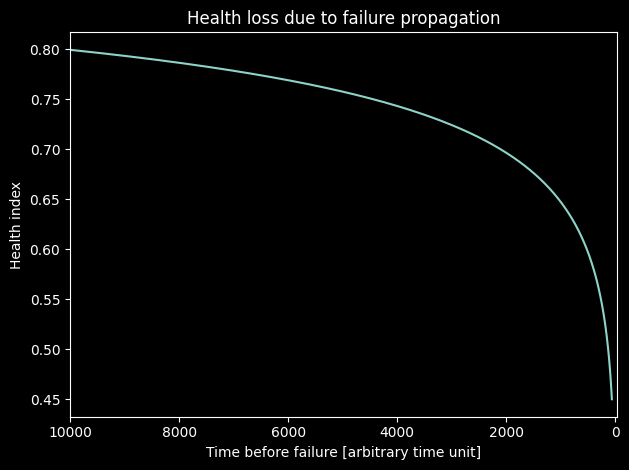

In [20]:
import math
from typing import Any, Iterable, Generator

import matplotlib.pyplot as plt
import numpy as np
from numpy import ndarray

t_max: int = 10000

d: float = 0.05
a: float = -0.3
b: float = 0.2
th: float = 0.45


def h_generator(ttf: int, d_val: float, a_val: float, b_val: float,
                th_val: float = 0.0) -> Generator[tuple[int, float], Any, None]:
    for time in range(ttf, -1, -1):
        h_val = 1 - d_val - math.exp(a_val * time ** b_val)
        if h_val < th_val:
            break
        yield time, h_val


h = h_generator(t_max, d, a, b, th)

plt.xlim(t_max, -30)
plt.plot(*zip(*h))
plt.title('Health loss due to failure propagation')
plt.ylabel('Health index')
plt.xlabel('Time before failure [arbitrary time unit]')
plt.tight_layout()
plt.show()

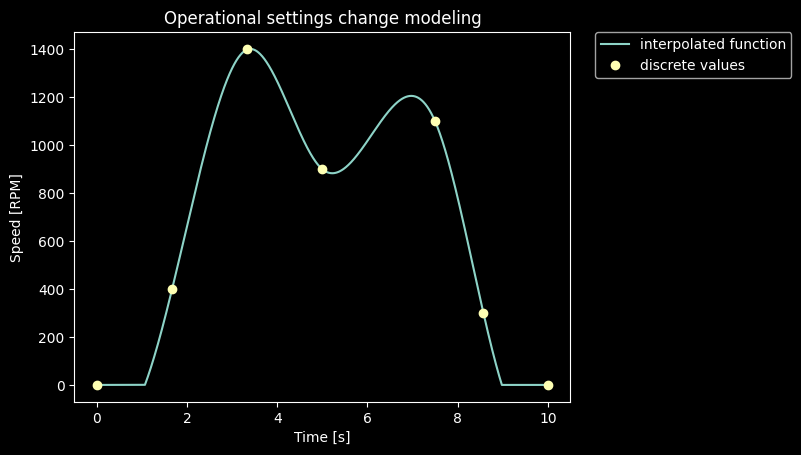

In [21]:
from scipy.interpolate import interp1d

t_max: int = 10  # (seconds)
sample_rate: int = 2 ** 10  # ~1kHz

t: ndarray = np.linspace(0, t_max, num=t_max * sample_rate, endpoint=False)

x: list[int | float] = [0, t_max / 6, t_max / 3, t_max / 2, t_max * 3 / 4, t_max * 6 / 7, t_max]  # points in time
values: ndarray = np.array([0, 400, 1400, 900, 1100, 300, 0])  # speeds at the given points in time

values_interpolated: interp1d = interp1d(x, values, kind='cubic')  # choosing 'linear' will produce a piecewise function

omega: Iterable | Any = values_interpolated(t)

# interpolation is not positive-preserving
omega[omega < 0] = 0

plt.title('Operational settings change modeling')
plt.ylabel('Speed [RPM]')
plt.xlabel('Time [s]')
plt.plot(t, omega, label='interpolated function')
plt.plot(x, values, 'o', label='discrete values')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

plt.show()

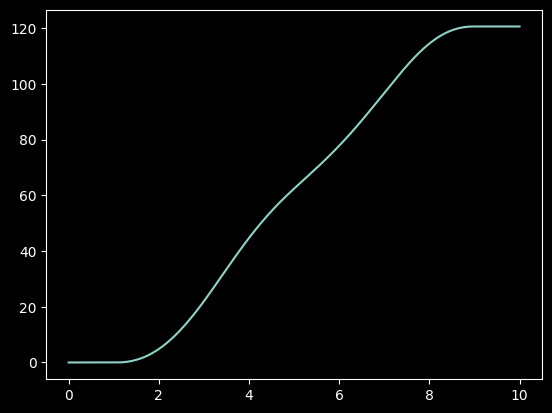

In [22]:
fi: ndarray = np.cumsum(omega / sample_rate) / 60
plt.plot(t, fi)
plt.show()

In [23]:
from IPython.display import Audio
from scipy import signal

w_normal: list[int] = [1, 2, 3, 4, 5, 12, 15]
A_normal: list[int | float] = [5, 8, 2 / 3, 9, 8, 13, 5]


def generate(fi: ndarray, wk: list[int], Ak: list[int | float], s: object = None) -> Any:
    N = len(fi)
    base = 2 * np.pi * fi
    b = np.array([np.sin(base * w) * a for w, a in zip(wk, Ak)])
    a = b.sum(axis=0)
    a = np.random.normal(-0.1, 0.1, N) + a
    if s is not None:
        a += s
    return np.int16(a / np.max(np.abs(a)) * 32767)


signal_pcm = generate(fi, w_normal, A_normal)


def as_audio(signal_pcm, sample_rate=sample_rate):
    audio_sample_rate = 8192
    if sample_rate != audio_sample_rate:
        signal_pcm = signal.resample(signal_pcm, len(signal_pcm) * int(audio_sample_rate / sample_rate))

    return Audio(signal_pcm, rate=audio_sample_rate, autoplay=False)


as_audio(signal_pcm)

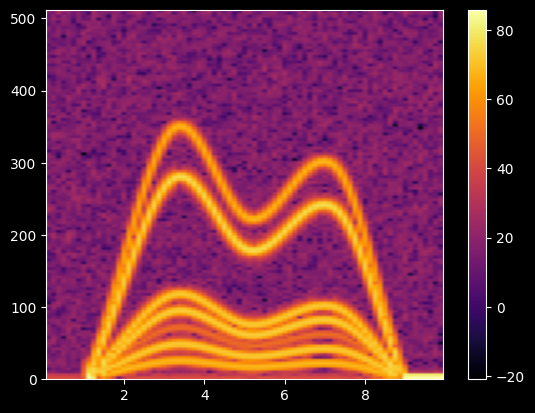

In [24]:
def spectrogram(signal, sample_rate):
    fig, ax = plt.subplots()
    cmap = plt.get_cmap('inferno')
    cmap.set_under(color='k', alpha=None)
    Pxx, freqs, bins, im = ax.specgram(signal, Fs=sample_rate, NFFT=256, cmap=cmap, mode='magnitude')
    fig.colorbar(im)
    plt.show()

spectrogram(signal_pcm, sample_rate)

# Data Generation

In [25]:
# import numpy as np


# from scipy.interpolate import interp1d

class VibrationSensorSignalSample:
    CUTOFF: int = 150

    def __init__(self, W, A, fundamental_from, fundamental_to, t=0, interval=1, previous_sample=None, sample_rate=1024):
        self.interval = interval
        self.sample_rate = sample_rate
        self.W = W
        self.A = A
        self.t = t
        self.base_frequency = fundamental_from
        self.target_base_frequency = fundamental_to
        self.add_noise = True
        self.__previous_sample = previous_sample
        self.__N = sample_rate * interval

    def pcm(self):
        ts = np.linspace(self.t, self.t + self.interval, num=self.__N, endpoint=False)

        x = np.array([0, self.interval]) + self.t
        points = np.array([self.base_frequency, self.target_base_frequency])
        rpm = interp1d(x, points, kind='linear')

        f = rpm(ts)
        f[f < 0] = 0

        fi = np.cumsum(f / self.sample_rate) + (self.__previous_sample.__last_cumsum if self.__previous_sample else 0)

        base = 2 * np.pi * fi
        b = np.array([np.sin(base * w) * a for w, a in zip(self.W, self.A)])
        a = b.sum(axis=0)

        if self.add_noise:
            a += np.random.normal(0, 0.1, self.__N)

        self.__last_cumsum = fi[-1]
        self.base_frequency = self.target_base_frequency

        a[a > self.CUTOFF] = self.CUTOFF
        a[a < -self.CUTOFF] = -self.CUTOFF

        return np.int16(a / self.CUTOFF * 32767)


class RotationalMachine:
    ambient_temperature: float = 20.0  # degrees Celsius
    max_temperature: float = 120.0
    ambient_pressure: float = 101.0  # kPa

    def __init__(self, name, h1, h2):
        self.W = [1 / 2, 1, 2, 3, 5, 7, 12, 18]
        self.A = [1, 5, 80, 2 / 3, 8, 2, 14, 50]
        self.t = 0
        self.name = name
        self.speed = 0
        self.speed_desired = 0
        self.temperature = RotationalMachine.ambient_temperature
        self.pressure = RotationalMachine.ambient_pressure
        self.pressure_factor = 2
        self.__vibration_sample = None
        self.__h1 = h1
        self.__h2 = h2
        self.broken = False

    def set_health(self, h1, h2):
        self.__h1 = h1
        self.__h2 = h2
        self.broken = False

    def set_speed(self, speed):
        self.speed_desired = speed

    def __g(self, v, min_v, max_v, target, rate):
        delta = (target - v) * rate
        return max(min(v + delta, max_v), min_v)

    def noise(self, magnitude):
        return random.uniform(-magnitude, magnitude)

    def next_state(self):
        try:
            _, h1 = next(self.__h1)
        except:
            self.broken = True
            raise Exception("F1")

        try:
            _, h2 = next(self.__h2)
        except:
            self.broken = True
            raise Exception("F2")

        v_from = self.speed / 60
        self.speed = (self.speed + (2 - h2) * self.speed_desired) / 2
        v_to = self.speed / 60

        self.temperature = (2 - h1) * self.__g(self.temperature, self.ambient_temperature, self.max_temperature,
                                               self.speed / 10, 0.01 * self.speed / 1000)
        self.pressure = h1 * self.__g(self.pressure, self.ambient_pressure, np.inf, self.speed * self.pressure_factor,
                                      0.3 * self.speed / 1000)
        self.__vibration_sample = VibrationSensorSignalSample(
            #self.W, self.A, v_from, v_to, t = self.t, previous_sample = self.__vibration_sample)
            self.W, self.A, v_from, v_to, t=self.t)

        state = {
            'speed_desired': self.speed_desired,
            'ambient_temperature': self.ambient_temperature + self.noise(0.1),
            'ambient_pressure': self.ambient_pressure + self.noise(0.1),
            'speed': self.speed + self.noise(5),
            'temperature': self.temperature + self.noise(0.1),
            'pressure': self.pressure + self.noise(20),
            'vibration': self.__vibration_sample
        }

        self.t += 1

        for key in state:
            value = state[key]
            if isinstance(value, (int, float)):
                state[key] = round(value, 2)

        return state

In [26]:
data_dir = 'data'

In [27]:
import random
import datetime
import pandas as pd
from dateutil import parser
from ipywidgets import IntProgress

# Simulation parameters
seed = 42
date_from = parser.parse("Jan 01 2026 12:00AM")
date_to = parser.parse("Feb 21 2026 12:00AM")
telemetry_batch_frequency = datetime.timedelta(hours = 1)
telemetry_interval = datetime.timedelta(seconds = 1)
machine_count = 1000
active_machines_per_batch = 33
cycle_length_min = 1
cycle_length_max = 5

random.seed(seed)

In [29]:
def create_machines(n):
    machines = []
    for i in range(n):
        ttf1 = random.randint(5000, 50000)
        ttf2 = random.randint(5000, 90000)

        h1 = h_generator(ttf1, d, a, b)
        h2 = h_generator(ttf2, d, a, b)

        m = RotationalMachine('M_{0:04d}'.format(i), h1, h2)
        machines.append(m)
    return machines


def sample(machines, m):
    return [machines[i] for i in sorted(random.sample(range(len(machines)), m))]


machines = create_machines(machine_count)

telemetry = []
errors = []

max_count = (date_to - date_from) / telemetry_batch_frequency
f = IntProgress(min=0, max=max_count, description='Simulation:')  # instantiate the bar
display(f)

while date_from + telemetry_batch_frequency < date_to:
    s = sample(machines, active_machines_per_batch)
    telemetry.clear()

    for m in s:
        if m.broken:
            # repair recorded
            ttf1 = random.randint(5000, 50000)
            h1 = h_generator(ttf1, d, a, b)

            ttf2 = random.randint(5000, 90000)
            h2 = h_generator(ttf2, d, a, b)
            m.set_health(h1, h2)

            errors.append({
                'timestamp': date_from,
                'machineID': m.name,
                'level': 'INFO',
                'code': 'fixed'
            })

            continue

        l = random.randint(cycle_length_min, cycle_length_max)
        offset = random.randint(0, 60 - l)
        m.set_speed(1000)
        duration = l * 60
        cooldown_point = duration - 20
        for i in range(duration):
            if i == cooldown_point:
                m.set_speed(0)

            ts = date_from + datetime.timedelta(seconds=offset * 60 + i)
            try:
                state = m.next_state()
                state['timestamp'] = ts
                state['machineID'] = m.name
                telemetry.append(state)
                if not state['speed']:
                    break
            except Exception as e:
                errors.append({
                    'timestamp': ts,
                    'machineID': m.name,
                    'level': 'CRITICAL',
                    'code': str(e)
                })
                break

    if telemetry:
        telemetry_df = pd.DataFrame(telemetry).drop('vibration', axis=1)
        telemetry_df.index = telemetry_df['timestamp']
        del telemetry_df['timestamp']
        suffix = date_from.strftime("%Y%m%d-%H%M%S")
        # INT96 timestamps are deprecated, but default INT64 timestamps are supported only since Spark 2.3.0
        telemetry_df.to_parquet('{0}/telemetry/telemetry-{1}.parquet'.format(data_dir, suffix), engine='fastparquet',
                                times='int96')
        del telemetry_df

    date_from += telemetry_batch_frequency
    f.value += 1

if errors:
    logs_df = pd.DataFrame(errors)
    sequence_count = len(logs_df[logs_df.level == 'CRITICAL'])
    logs_df.index = logs_df['timestamp']
    del logs_df['timestamp']
    logs_df.to_parquet(data_dir + '/logs/logs.parquet', engine='fastparquet', times='int96')
    print('{0} run-to-failure sequence(s) generated.'.format(sequence_count))
else:
    print('WARNING: Simulation produced no run-to-failure sequences.')


IntProgress(value=0, description='Simulation:', max=1224)

71 run-to-failure sequence(s) generated.
